<a href="https://colab.research.google.com/github/sabriddinovna/graph_nn/blob/main/aboutpointNet%2B%2B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
import os
os.environ['TORCH']=torch.__version__
print(torch.__version__)

2.11.0+cpu


In [3]:
!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-cluster -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.1/682.1 kB 11.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 828.0/828.0 kB 13.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [10]:
def visualize_mesh(pos, face):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    ax.axes.xaxis.set_ticklabels([])
    ax.axes.yaxis.set_ticklabels([])
    ax.axes.zaxis.set_ticklabels([])
    ax.plot_trisurf(pos[:, 0], pos[:, 1], pos[:, 2], triangles=face.t(), antialiased=False)
    plt.show()

In [11]:
def visualize_points(pos, edge_index=None, index=None):
    fig = plt.figure(figsize=(4, 4))
    if edge_index is not None:
        for (src, dst) in edge_index.t().tolist():
             src = pos[src].tolist()
             dst = pos[dst].tolist()
             plt.plot([src[0], dst[0]], [src[1], dst[1]], linewidth=1, color='black')
    if index is None:
        plt.scatter(pos[:, 0], pos[:, 1], s=50, zorder=1000)
    else:
       mask = torch.zeros(pos.size(0), dtype=torch.bool)
       mask[index] = True
       plt.scatter(pos[~mask, 0], pos[~mask, 1], s=50, color='lightgray', zorder=1000)
       plt.scatter(pos[mask, 0], pos[mask, 1], s=50, zorder=1000)
    plt.axis('off')
    plt.show()


In [12]:
from torch_geometric.datasets import  GeometricShapes
dataset=GeometricShapes(root='data/GeoometricShapes')
print(dataset)

GeometricShapes(40)


Data(pos=[16, 3], face=[3, 14], y=[1])


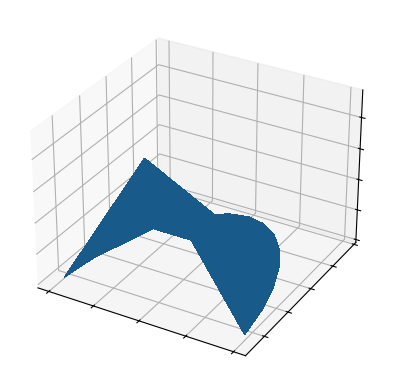

In [13]:
data=dataset[5]
print(data)
visualize_mesh(data.pos, data.face)

In [14]:
import torch
from torch_geometric.transforms import SamplePoints

torch.manual_seed(4678)
dataset.transform=SamplePoints(num=256)


Data(pos=[256, 3], y=[1])


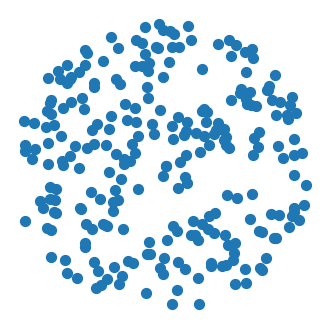

Data(pos=[256, 3], y=[1])


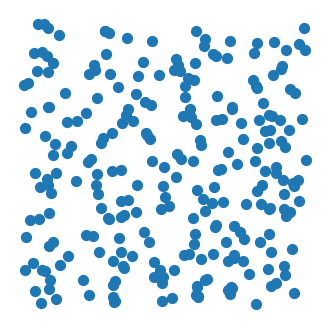

In [15]:
data = dataset[0]
print(data)
visualize_points(data.pos, data.edge_index)

data = dataset[4]
print(data)
visualize_points(data.pos)

In [16]:
from torch_cluster import knn_graph


In [17]:
data=dataset[0]

torch.Size([2, 1536])


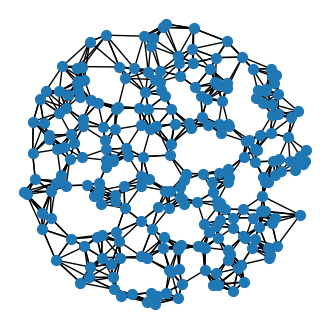

torch.Size([2, 1536])


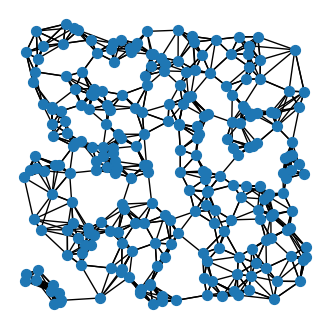

In [18]:
data.edge_index = knn_graph(data.pos, k=6)
print(data.edge_index.shape)
visualize_points(data.pos, edge_index=data.edge_index)

data = dataset[4]
data.edge_index = knn_graph(data.pos, k=6)
print(data.edge_index.shape)
visualize_points(data.pos, edge_index=data.edge_index)

In [19]:
from torch.nn import Sequential,Linear,ReLU
from torch_geometric.nn import MessagePassing

class PointNetLayer(MessagePassing):
  def __init__(self, in_channels, out_channels):
    super().__init__(aggr='max')

    self.mlp=Sequential(Linear(in_channels+3, out_channels),
                        ReLU(), Linear(out_channels, out_channels))

  def forward(self, h, pos, edge_index):
    return self.propagate(edge_index, h=h, pos=pos)

  def message(self, h_j, pos_j, pos_i):
    input=pos_j-pos_i

    if h_j is not None:
      input=torch.cat([h_j, input], dim=-1)

    return self.mlp(input)

In [20]:
import torch
import torch.nn.functional as F
from torch_cluster import knn_graph
from torch_geometric.nn import global_max_pool

In [23]:
class PointNet(torch.nn.Module):
  def __init__(self):
    super().__init__()

    torch.manual_seed(463832)
    self.conv1=PointNetLayer(3,32)
    self.conv2=PointNetLayer(32,32)
    self.classifier=Linear(32, dataset.num_classes)

  def forward(self, pos,batch):
    edge_index=knn_graph(pos,  k=16, batch=batch, loop=True)

    h=self.conv1(h=pos, pos=pos, edge_index=edge_index)
    h=h.relu()
    h=self.conv2(h=h, pos=pos,  edge_index=edge_index)
    h=h.relu()

    h=global_max_pool(h, batch)

    return self.classifier(h)

In [24]:
model=PointNet()
print(model)

PointNet(
  (conv1): PointNetLayer()
  (conv2): PointNetLayer()
  (classifier): Linear(in_features=32, out_features=40, bias=True)
)


In [25]:
from IPython.display import Javascript  # Restrict height of output cell.
display(Javascript('''google.colab.output.setIframeHeight(0, true, {maxHeight: 300})'''))


<IPython.core.display.Javascript object>

at the end, I understood ,  currently I dont need to learn it in detail.